## Step 0: Load the Python packages

This cell loads the tools the notebook uses. You don't need to change anything.

In [1]:
# --- Standard Python tools (come with Python) ---
from pathlib import Path        # build and check file/folder paths

# --- Scientific Python tools ---
import numpy as np              # numbers and arrays (lists of numbers you can do math on)
import pandas as pd             # tables
import matplotlib.pyplot as plt # plotting
from IPython.display import display   # shows a table nicely in the notebook

# --- MNE-Python: the MEG analysis package ---
import mne

# --- MNE-BIDS: reads BIDS files together with their sidecar files (Step 2) ---
import mne_bids

# Only show MNE's warnings and errors (not every info message)
mne.set_log_level("WARNING")

# Draw plots inside the notebook
%matplotlib inline

print("MNE version:", mne.__version__)
print("MNE-BIDS version:", mne_bids.__version__)

MNE version: 1.13.2
MNE-BIDS version: 0.20.0


## Step 1: Settings ✏️ (edit this cell)

Everything you normally need to change is in the cell below. 

In [5]:
# ---------------------------------------------------------------------------
# WHICH RECORDING
# ---------------------------------------------------------------------------
#BIDS_ROOT = Path("/jukebox/[yourpath]/auditory-oddball/bids")  # top folder of your BIDS dataset
BIDS_ROOT = Path("Y:/Alessia/pygers-meg/data/auditory-oddball/bids")
SUBJECT = "001"           # the part after "sub-"  (as text, in quotes)
SESSION = "001"           # the part after "ses-"; use None (no quotes) if you have no sessions
TASK = "oddballftcued"   # the part after "task-"
RUN = None               # the part after "run-", e.g. "01"; use None if there is no run label
EYESYNC_DERIV = "eyesync"    # the derivatives folder notebook 05 wrote the synced MEG file to
SENSORQC_DERIV = "sensorqc"  # the derivatives folder notebook 01 wrote the bad channels and breaks to (Step 2c)
FILTERED_DERIV = "filtered"  # the derivatives folder this notebook saves the filtered, downsampled recording to (Step 4)

# ---------------------------------------------------------------------------
# FILTER AND DOWNSAMPLE (Step 3)
# ---------------------------------------------------------------------------
HIGHPASS_HZ = 0.1               # remove slow drifts below this frequency (Hz)
TARGET_SFREQ = 600.0            # the new sampling rate (Hz); the recording is at 1200 Hz
LOWPASS_HZ = TARGET_SFREQ / 3   # 200 Hz: removes what can't be represented at the new rate (see Step 3)

# ---------------------------------------------------------------------------
# SAVING (Step 4)
# ---------------------------------------------------------------------------
OVERWRITE = False               # True: replace the saved recording from an earlier run of this notebook

## Step 2: Find the file and load the data

This cell works out the path of the synced MEG file from your settings, checks it exists, and reads it.
If something is wrong it stops with a message that says what to fix.

`raw.load_data()` reads all the data into memory. This notebook needs that, because it filters and resamples
the whole recording. A long recording can take a minute or two to load.

Step 2b then repairs the description of the eye-tracker channels, which `read_raw_bids` loads incomplete.

In [6]:
BIDS_ROOT = Path(BIDS_ROOT)

if "[yourpath]" in str(BIDS_ROOT):
    raise ValueError("BIDS_ROOT still contains the [yourpath] placeholder. Set it in Step 1.")

# ---- The BIDS-style name of this recording, e.g. sub-01_ses-01_task-oddball ------------------
sub_ses = [f"sub-{SUBJECT}"] + ([f"ses-{SESSION}"] if SESSION else [])   # folder levels
name_parts = sub_ses + [f"task-{TASK}"] + ([f"run-{RUN}"] if RUN else [])
base = "_".join(name_parts)        # the start of every file name for this recording
sub_dir = Path(*sub_ses)           # e.g. sub-01/ses-01

# ---- The synced MEG file from notebook 05 (MEG + eye channels) --------------------------------
eyesync_root = BIDS_ROOT / "derivatives" / EYESYNC_DERIV
# BIDSPath describes a file by its BIDS labels. Notebook 05 labels the synced file "proc-eyesync"
# (proc: a processed version of this recording).
bids_path = mne_bids.BIDSPath(root=eyesync_root, subject=SUBJECT, session=SESSION, task=TASK, run=RUN,
                              processing="eyesync", datatype="meg", suffix="meg", extension=".fif")
# FIF files can't be bigger than 2 GB, so MNE saves a longer recording in parts:
# ..._split-01_meg.fif, ..._split-02_meg.fif, ... We open the first part and MNE finds the others itself.
if not bids_path.fpath.is_file() and bids_path.copy().update(split="01").fpath.is_file():
    bids_path.update(split="01")
meg_file = bids_path.fpath
meg_dir = meg_file.parent

if not meg_file.is_file():
    found = sorted(meg_dir.glob("*_meg.fif")) if meg_dir.is_dir() else []
    raise FileNotFoundError(f"Synced MEG file not found:\n    {meg_file}\nHas notebook 05 been run for this "
                            "session? FIF files in that folder: " + (", ".join(p.name for p in found) or "none"))

# ---- The synced recording's _channels.tsv (written by notebook 05, next to the FIF file) -----------
# It lists every channel, the eye-tracking ones included, with any channels already marked bad and why.
# Notebook 01 saved an updated copy, with its bad channels, in derivatives/sensorqc/ (used in Step 2c).
bids_channels_tsv = bids_path.copy().update(split=None, suffix="channels", extension=".tsv").fpath
if not bids_channels_tsv.is_file():
    raise FileNotFoundError(f"The synced recording's _channels.tsv was not found:\n    {bids_channels_tsv}\n"
                            "Re-run notebook 05 for this session; newer versions write it.")

# ---- Read it --------------------------------------------------------------------------------
# read_raw_bids reads the FIF file together with its sidecar files in derivatives/eyesync/: the channel types
# and bad channels come from _channels.tsv, and the task and eye-tracking events from _events.tsv (they appear
# as annotations).
#
# You will see one warning here, "participants.tsv file not found". It is expected and harmless:
# read_raw_bids also looks for participants.tsv (age, sex, handedness, ...) in the top folder of the dataset
# it reads from, to copy those details into the recording's header. Here that folder is derivatives/eyesync/,
# but participants.tsv only exists at the top of the main BIDS dataset, so it isn't found and those details
# are not added. Nothing in this notebook uses them.
raw = mne_bids.read_raw_bids(bids_path)
raw.load_data()   # read the data themselves into memory (the steps below need them)

print("Loaded:", meg_file)

if len(raw.filenames) > 1:
    print(f"(the recording is split into {len(raw.filenames)} files; MNE read them all)")

# read_raw_bids loses the coil type of the eye-tracker channels (see notebook 01, Step 2b);
# the FIF file's own header still has it, so copy it back. No file is changed.
header = mne.io.read_info(meg_file, verbose=False)     # header only: quick, no data
for ch_in_file in header["chs"]:
    ch = raw.info["chs"][raw.ch_names.index(ch_in_file["ch_name"])]
    if ch["kind"] == ch_in_file["kind"]:
        ch["coil_type"] = ch_in_file["coil_type"]

types = dict(zip(raw.ch_names, raw.get_channel_types()))   # errors if the repair didn't work
print("Eye-tracker channels:", {n: t for n, t in types.items() if t in ("eyegaze", "pupil")})


C:\Users\as9813\AppData\Local\Temp\ipykernel_34176\4001821497.py:48: RuntimeWarning: participants.tsv file not found for Y:\Alessia\pygers-meg\data\auditory-oddball\bids\derivatives\eyesync\sub-001\ses-001\meg\sub-001_ses-001_task-oddballftcued_proc-eyesync_split-01_meg.fif
  raw = mne_bids.read_raw_bids(bids_path)


Loaded: Y:\Alessia\pygers-meg\data\auditory-oddball\bids\derivatives\eyesync\sub-001\ses-001\meg\sub-001_ses-001_task-oddballftcued_proc-eyesync_split-01_meg.fif
(the recording is split into 2 files; MNE read them all)
Eye-tracker channels: {'ET_xpos': 'eyegaze', 'ET_ypos': 'eyegaze', 'ET_pupil': 'pupil'}


In [9]:
# make sure everything is okay
print(raw)
print(raw.info)

<Raw | sub-001_ses-001_task-oddballftcued_proc-eyesync_split-01_meg.fif, 233 x 3742080 (3118.4 s), ~6.51 GiB, data loaded>
<Info | 16 non-empty values
 bads: []
 ch_names: Trigger1[Z], Trigger2[Z], Trigger3[Z], Trigger4[Z], Trigger5[Z], ...
 chs: 20 Stimulus, 12 misc, 192 Magnetometers, 6 Reference Magnetometers, 2 Eye-tracking (Gaze position), 1 Eye-tracking (Pupil size)
 custom_ref_applied: False
 description: Anonymized using a time shift to preserve age at acquisition
 dev_head_t: MEG device -> head transform
 device_info: 2 items (dict)
 dig: 50347 items (3 Cardinal, 50344 Extra)
 experimenter: mne_anonymize
 file_id: 4 items (dict)
 highpass: 0.0 Hz
 line_freq: 60.0
 lowpass: 600.0 Hz
 meas_date: 1916-08-26 17:40:22 UTC
 meas_id: 4 items (dict)
 nchan: 233
 projs: []
 sfreq: 1200.0 Hz
 subject_info: <subject_info | >
>


## Step 2c: Take the bad channels and breaks from notebook 01

`read_raw_bids` set the bad channels from notebook 05's `_channels.tsv` in `derivatives/eyesync/`. That list is
from **before** the sensor-quality checks of notebook 01. Notebook 01 saved the up-to-date list, with a reason for
each channel, in `derivatives/sensorqc/` (its Step 7c). This cell replaces the bad channels with that list.

It also adds the **breaks** between blocks that notebook 01 found (its Step 7a), as `BAD_break` annotations. Like
every annotation starting with `BAD`, they are left out of later steps (for example epoching and ICA).

Both have to be in place before Step 4 saves the recording, so every later notebook gets them too.

In [ ]:
sensorqc_root = BIDS_ROOT / "derivatives" / SENSORQC_DERIV
sensorqc_dir = sensorqc_root / sub_dir / "meg"
# Notebook 01 named its files after the recording they describe, so they all start with eyesync_base
eyesync_base = f"{base}_proc-eyesync"
sensorqc_channels_tsv = sensorqc_dir / f"{eyesync_base}_channels.tsv"      # bad channels, with reasons
breaks_tsv = sensorqc_dir / f"{eyesync_base}_desc-breaks_events.tsv"      # breaks between blocks
for needed in (sensorqc_channels_tsv, breaks_tsv):
    if not needed.is_file():
        raise FileNotFoundError(f"Not found:\n    {needed}\nRun notebook 01 for this session first (its Step 7c saves it).")

# ---- Bad channels -------------------------------------------------------------------------------
sensorqc_channels = pd.read_csv(sensorqc_channels_tsv, sep="\t", dtype=str, keep_default_na=False)   # all as text
not_in_raw = sorted(set(sensorqc_channels["name"]) - set(raw.ch_names))
if not_in_raw:
    raise ValueError(f"{sensorqc_channels_tsv.name} lists channels that are not in the recording: {not_in_raw}")
bads_from_eyesync = list(raw.info["bads"])
raw.info["bads"] = list(sensorqc_channels.loc[sensorqc_channels["status"] == "bad", "name"])

print("Bad channels from eyesync (before notebook 01):", bads_from_eyesync or "none")
print(f"Bad channels from sensorqc (used from now on): {len(raw.info['bads'])}")
display(sensorqc_channels.loc[sensorqc_channels["status"] == "bad", ["name", "status_description"]]
        .rename(columns={"name": "channel", "status_description": "reason"}).reset_index(drop=True))

# ---- Breaks -------------------------------------------------------------------------------------
# The onsets in the file count from the first sample of the recording. When the recording has a measurement date,
# MNE counts annotation onsets from that date instead, which is first_time earlier.
breaks = pd.read_csv(breaks_tsv, sep="\t")
onset_shift = raw.first_time if raw.annotations.orig_time is not None else 0.0
# Remove BAD_break annotations from an earlier run of this cell, so re-running it doesn't add them twice
raw.annotations.delete(np.flatnonzero(raw.annotations.description == "BAD_break"))
if len(breaks):
    raw.annotations.append(breaks["onset"].to_numpy() + onset_shift, breaks["duration"].to_numpy(),
                           breaks["trial_type"].to_numpy())
print(f"\n{len(breaks)} break(s) added as BAD_break:")
display(breaks)

## Step 3: Filter and downsample

The recording is sampled at 1200 Hz. Down-sampling lowers that to `TARGET_SFREQ` (600 Hz), which halves the size of the
data and makes every later step faster. This step follows the FLUX pipeline's down-sampling step.

**Why filter first.** At a sampling rate of 600 Hz, the highest frequency the data can represent is half of that,
300 Hz (the *Nyquist frequency*). Anything faster that is still in the signal doesn't disappear when you
downsample: it folds back and shows up as a fake slower signal (*aliasing*). So we first remove everything above
`LOWPASS_HZ` with a low-pass filter. Filters don't cut off sharply, so the cutoff is set well below 300 Hz: FLUX
uses one third of the new sampling rate, here 600 / 3 = **200 Hz**. That keeps all brain activity up to 200 Hz,
more than enough for auditory evoked responses.

**The high-pass filter** at `HIGHPASS_HZ` (0.1 Hz) removes the slow drifts in the OPM signals at the same time.

Both are done by one **FIR filter** (MNE's default). MNE applies it forwards and backwards (*zero-phase*), so it
doesn't shift the signals in time.

**A copy, `raw_filt`.** The filtering and downsampling are done on a copy of the recording, `raw_filt`. `raw` keeps
the unfiltered data at 1200 Hz, so Step 3b can compare the two, and you can change the filter settings in Step 1
and run this cell again without reloading the data. From here on, `raw_filt` is the recording that gets saved.
Keeping both needs more memory: twice as much as `raw` alone while filtering (the copy is at the full rate
until it is downsampled), then about 1.5 times as much.

**Which channels.** `filter()` filters the MEG sensors and the reference sensors. The eye-tracker, trigger and
other channels are left as they are. `resample()` then changes the sampling rate of **every** channel; it
applies its own anti-aliasing for the channels that weren't filtered.

**The events stay correct.** The task and eye-tracking events were decoded by notebook 05 at the original
1200 Hz and loaded in Step 2 as **annotations**, which are stored in seconds, not samples. Resampling doesn't move
them. Two things to remember from now on:

- To get an events array, use `mne.events_from_annotations(raw)`. Don't decode the trigger channel `STI101`
  again with `mne.find_events`: resampling smears its sharp edges, so the timing would no longer be reliable.
- The `sample` column of notebook 05's `_events.tsv` counts samples at 1200 Hz, so it no longer matches the data.

You may see a warning that resampling the stim channels "caused event information to become unreliable". It is
expected, for the reason above: we don't use those channels for timing.

Filtering 52 minutes of data takes a few minutes. The check in Step 3b compares a 60 s piece of `raw` and
`raw_filt`.

In [7]:
orig_sfreq = raw.info["sfreq"]
new_nyquist = TARGET_SFREQ / 2
if TARGET_SFREQ >= orig_sfreq:
    raise ValueError(f"TARGET_SFREQ ({TARGET_SFREQ} Hz) must be lower than the recording's rate ({orig_sfreq} Hz).")
if LOWPASS_HZ >= new_nyquist:
    raise ValueError(f"LOWPASS_HZ ({LOWPASS_HZ} Hz) must be below the new Nyquist frequency ({new_nyquist} Hz).")

# ---- Filter, then downsample, a copy of raw ---------------------------------------------------------------
# raw stays unfiltered at the original rate, so this cell can be run again with other settings.
print(f"Filtering {HIGHPASS_HZ}-{LOWPASS_HZ:g} Hz ...")
raw_filt = raw.copy().filter(l_freq=HIGHPASS_HZ, h_freq=LOWPASS_HZ)   # FIR, zero-phase; MEG + reference sensors
print(f"Resampling {orig_sfreq:g} Hz -> {TARGET_SFREQ:g} Hz ...")
raw_filt.resample(TARGET_SFREQ)                                      # every channel; the annotations stay in place

print(f"\nSampling rate: {raw.info['sfreq']:g} Hz -> {raw_filt.info['sfreq']:g} Hz")
print(f"Samples:       {raw.n_times:,} -> {raw_filt.n_times:,}")
print(f"Filter stored in raw_filt.info: high-pass {raw_filt.info['highpass']:g} Hz, "
      f"low-pass {raw_filt.info['lowpass']:g} Hz")

Filtering 0.1-200 Hz ...
Resampling 1200 Hz -> 600 Hz ...

Sampling rate: 1200 Hz -> 600 Hz
Samples:       3,742,080 -> 1,871,040
Filter stored in raw.info: high-pass 0.1 Hz, low-pass 200 Hz


### Step 3b: Check the result

- **Events:** the annotations of `raw_filt` must be exactly the same as those of `raw`. The table then compares the
  events MNE derives from them, in samples, in `raw` (1200 Hz) and in `raw_filt` (600 Hz). At 600 Hz an event can
  only fall on a sample, so its time may move to the nearest one: by at most half a sample, 0.83 ms. The line below
  the table checks this for every event, the eye-tracking ones included.
- **Spectrum:** the power spectrum of the MEG sensors over the same 60 s, in `raw` (before) and `raw_filt` (after). Below 200 Hz the two
  curves should lie on top of each other; above 200 Hz the filtered data drop away, and they end at the new
  Nyquist frequency (300 Hz). The left plot shows the whole spectrum with frequency on a log axis, so the low
  frequencies get as much room as the high ones. The right plot zooms in on the low-pass with a linear axis, up to
  the original Nyquist frequency (600 Hz), so you can see where the filtered data drop away and that nothing
  is left above 300 Hz. The slow drifts below 0.1 Hz are removed too, but the spectrum can't show
  frequencies that low; the high-pass mostly shows as traces that no longer wander off when you browse the data.

Annotations unchanged: True (3332 annotations)


,event,sample at 1200 Hz,time at 1200 Hz (s),sample at 600 Hz,time at 600 Hz (s),shift (ms)
0,right cue,7375,6.145833,3687,6.145000,-0.833
1,standard,7996,6.663333,3998,6.663333,0.000
2,standard,9356,7.796667,4678,7.796667,0.000
3,standard,10757,8.964167,5379,8.965000,0.833
4,standard,12167,10.139167,6084,10.140000,0.833


All 3330 events: largest shift 0.833 ms (at most half a sample, 0.833 ms: True)
Task events per type: {'blink': 300, 'deviant': 300, 'left cue': 150, 'right cue': 150, 'standard': 1463}


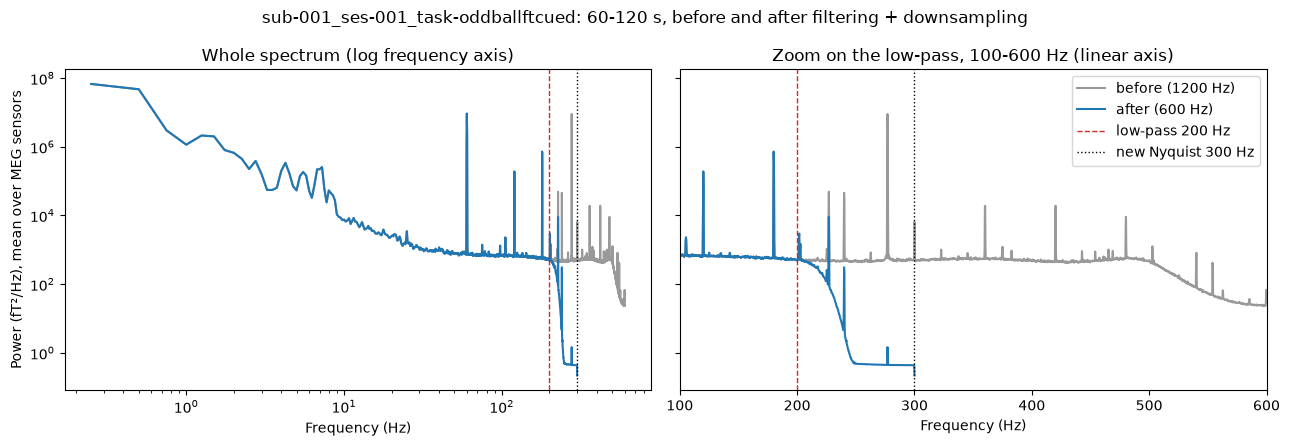

Note: no notch filter was applied, so the 60 Hz line noise (and harmonics) is still present. It will be removed in notebook 03.


In [19]:
# ---- Events -------------------------------------------------------------------------------------------
same = (len(raw_filt.annotations) == len(raw.annotations)
        and np.allclose(raw_filt.annotations.onset, raw.annotations.onset)
        and list(raw_filt.annotations.description) == list(raw.annotations.description))
print("Annotations unchanged:", same, f"({len(raw_filt.annotations)} annotations)")

# The same annotations turned into events (sample numbers) in both recordings, with the same codes
events_orig, event_id = mne.events_from_annotations(raw)
events, _ = mne.events_from_annotations(raw_filt, event_id=event_id)
if len(events) != len(events_orig) or not np.array_equal(events[:, 2], events_orig[:, 2]):
    raise RuntimeError("raw and raw_filt don't give the same list of events: re-run Step 3.")

def event_times(ev, rec):
    # sample number -> seconds from the first stored sample
    return (ev[:, 0] - rec.first_samp) / rec.info["sfreq"]

shift_ms = (event_times(events, raw_filt) - event_times(events_orig, raw)) * 1000
half_sample_ms = 1000 / (2 * raw_filt.info["sfreq"])

task_events = {k: v for k, v in event_id.items() if not k.startswith(("ET_", "BAD_"))}
task_rows = np.flatnonzero(np.isin(events[:, 2], list(task_events.values())))[:5]   # the first 5 task events
names = {v: k for k, v in event_id.items()}
sfreq_orig, sfreq_new = raw.info["sfreq"], raw_filt.info["sfreq"]
display(pd.DataFrame({
    "event": [names[c] for c in events[task_rows, 2]],
    f"sample at {sfreq_orig:g} Hz": events_orig[task_rows, 0],
    f"time at {sfreq_orig:g} Hz (s)": event_times(events_orig, raw)[task_rows],
    f"sample at {sfreq_new:g} Hz": events[task_rows, 0],
    f"time at {sfreq_new:g} Hz (s)": event_times(events, raw_filt)[task_rows],
    "shift (ms)": shift_ms[task_rows].round(3),
}))
print(f"All {len(events)} events: largest shift {np.abs(shift_ms).max():.3f} ms "
      f"(at most half a sample, {half_sample_ms:.3f} ms: {np.abs(shift_ms).max() <= half_sample_ms + 1e-6})")
print("Task events per type:", {k: int(np.sum(events[:, 2] == v)) for k, v in task_events.items()})

# ---- Spectrum before and after ----------------------------------------------------------------------------
CHECK_TMIN, CHECK_TMAX = 60.0, 120.0      # the 60 s piece of data used for the comparison (seconds)
psd_kwargs = dict(picks="mag", exclude="bads", tmin=CHECK_TMIN, tmax=CHECK_TMAX, fmin=0.25)
# 4 s windows (0.25 Hz resolution) at each recording's own sampling rate
psd_before = raw.compute_psd(n_fft=int(4 * raw.info["sfreq"]), **psd_kwargs)
psd_after = raw_filt.compute_psd(n_fft=int(4 * raw_filt.info["sfreq"]), **psd_kwargs)

# Left: the whole spectrum, frequency on a log axis (each factor of 10 gets the same width).
# Right: zoom on the low-pass, frequency on a linear axis (each Hz gets the same width).
ZOOM_FMIN = LOWPASS_HZ / 2                 # left edge of the zoom (Hz): 100 Hz with the default settings
fig, (ax_all, ax_zoom) = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for psd, label, color in [(psd_before, f"before ({orig_sfreq:g} Hz)", "0.6"),
                          (psd_after, f"after ({raw_filt.info['sfreq']:g} Hz)", "C0")]:
    power = psd.get_data().mean(axis=0) * 1e30                       # T²/Hz -> fT²/Hz
    ax_all.plot(psd.freqs, power, color=color, label=label)
    zoom = psd.freqs >= ZOOM_FMIN
    ax_zoom.plot(psd.freqs[zoom], power[zoom], color=color, label=label)
for ax in (ax_all, ax_zoom):
    ax.axvline(LOWPASS_HZ, color="C3", ls="--", lw=1, label=f"low-pass {LOWPASS_HZ:g} Hz")
    ax.axvline(new_nyquist, color="k", ls=":", lw=1, label=f"new Nyquist {new_nyquist:g} Hz")
    ax.set(yscale="log", xlabel="Frequency (Hz)")
ax_all.set(xscale="log", ylabel="Power (fT²/Hz), mean over MEG sensors", title="Whole spectrum (log frequency axis)")
ax_zoom.set(xlim=(ZOOM_FMIN, orig_sfreq / 2), title=f"Zoom on the low-pass, {ZOOM_FMIN:g}-{orig_sfreq / 2:g} Hz (linear axis)")
ax_zoom.legend()
fig.suptitle(f"{base}: {CHECK_TMIN:g}-{CHECK_TMAX:g} s, before and after filtering + downsampling")
fig.tight_layout()
plt.show()

print("Note: no notch filter was applied, so the 60 Hz line noise (and harmonics) is still present. It will be removed in notebook 03.")

## Step 4: Save the filtered, downsampled recording

The filtered, downsampled data so far exist only in memory. This step saves them as a new recording in
`derivatives/filtered/`, next to the other derivatives. The raw BIDS dataset and `derivatives/eyesync/` are not
changed, so you can always go back and filter again with other settings.

The new recording is labelled `proc-filt`, like notebook 05's `proc-eyesync`:

```
derivatives/filtered/sub-001/ses-001/meg/sub-001_ses-001_task-oddballftcued_proc-filt_meg.fif
```

At 600 Hz the recording is about half the size, under the 2 GB limit of a FIF file, so it is usually a single
file. A longer one would be split into `..._split-01_meg.fif`, `..._split-02_meg.fif`, as before.

Next to it, this step writes the BIDS sidecar files, so `read_raw_bids` can load it the way Step 2 loaded the
eyesync recording, and so the files say how they were made:

| File | What's in it |
|---|---|
| `_meg.json` | notebook 05's, with the new `SamplingFrequency` and `RecordingDuration`; **`SoftwareFilters`** records the band-pass filter and the downsampling (from which rate, to which rate, how); **`Sources`** lists the eyesync FIF file(s) and the sensorqc files this recording was made from |
| `_channels.tsv` | notebook 01's (sensorqc) list, with the bad channels and their reasons, the new `sampling_frequency`, and the filter in `low_cutoff` / `high_cutoff` |
| `_events.tsv` | notebook 05's events plus the breaks (Step 2c), with the `sample` column recomputed at the new rate. `read_raw_bids` builds the annotations from this file only, so the breaks must be in it |
| `_coordsystem.json`, `_channels.json`, `_events.json` | copied from eyesync (the `_events.json` describes `BAD_break` too) |
| `dataset_description.json` | in `derivatives/filtered/`: what made this folder, and links to the `raw`, `eyesync` and `sensorqc` datasets |

If the recording already exists from an earlier run, this step stops, unless you set `OVERWRITE = True` in Step 1.
Saving about 1.7 GB to the server takes a few minutes.

In [16]:
import json, shutil
from datetime import datetime

new_sfreq = raw_filt.info["sfreq"]
if new_sfreq != TARGET_SFREQ:
    raise RuntimeError(f"The data are at {new_sfreq:g} Hz, not TARGET_SFREQ ({TARGET_SFREQ:g} Hz). Run Step 3 first.")

filtered_root = BIDS_ROOT / "derivatives" / FILTERED_DERIV
out_dir = filtered_root / sub_dir / "meg"
out_base = f"{base}_proc-filt"                  # every file name of the new recording starts with this
out_fif = out_dir / f"{out_base}_meg.fif"

def uri(dataset, file):
    # A BIDS URI, e.g. "bids:eyesync:sub-001/ses-001/meg/..._meg.fif" ("eyesync" as named in DatasetLinks)
    return f"bids:{dataset}:{(sub_dir / 'meg' / Path(file).name).as_posix()}"

eyesync_fifs = [Path(f) for f in raw.filenames]          # the eyesync file(s) Step 2 read (raw, not raw_filt)
sources = ([uri("eyesync", f) for f in eyesync_fifs]
           + [uri("sensorqc", sensorqc_channels_tsv), uri("sensorqc", breaks_tsv)])

# ---- dataset_description.json -------------------------------------------------------------------------
raw_version = json.loads((BIDS_ROOT / "dataset_description.json").read_text()).get("BIDSVersion")
description = {
    "Name": "Filtered and downsampled OPM-MEG",
    "BIDSVersion": raw_version,
    "DatasetType": "derivative",
    "GeneratedBy": [{"Name": "02_Downsample_Filter.ipynb (Pygers-MEG)",
                     "Description": "Band-pass FIR filter, then downsampling; the settings of each recording are "
                                    "in its _meg.json (SoftwareFilters)"}],
    "DatasetLinks": {"raw": "../../", "eyesync": f"../{EYESYNC_DERIV}/", "sensorqc": f"../{SENSORQC_DERIV}/"},
}
out_dir.mkdir(parents=True, exist_ok=True)
(filtered_root / "dataset_description.json").write_text(json.dumps(description, indent=4))

# ---- The FIF file(s) -----------------------------------------------------------------------------------
# split_naming="bids": if the recording is over 2 GB, the parts are named ..._proc-filt_split-01_meg.fif, ...
print(f"Saving {out_fif.name} ...")
saved = [Path(p) for p in raw_filt.save(out_fif, split_naming="bids", overwrite=OVERWRITE)]
for p in saved:
    print(f"Saved: {p.name} ({p.stat().st_size / 1e9:.2f} GB)")
# Parts from an earlier run that this run did not write (e.g. a split-02 no longer needed) would be confusing
saved_set = {p.resolve() for p in saved}
leftovers = [p for p in sorted(out_dir.glob(f"{out_base}*_meg.fif")) if p.resolve() not in saved_set]
if leftovers:
    print("These FIF files are left over from an earlier run. Delete them:", [p.name for p in leftovers])

written = []

# ---- _meg.json: notebook 05's, updated ------------------------------------------------------------------
meg_json = json.loads((meg_dir / f"{eyesync_base}_meg.json").read_text(encoding="utf-8"))
meg_json["SamplingFrequency"] = new_sfreq
meg_json["RecordingDuration"] = float(raw_filt.times[-1])
meg_json["SoftwareFilters"] = {
    "Band-pass filter": {
        "HighpassCutoffHz": HIGHPASS_HZ,
        "LowpassCutoffHz": LOWPASS_HZ,
        "FilterType": "FIR, zero-phase (MNE-Python default design: firwin, Hamming window, automatic length "
                      "and transition bandwidths)",
        "Function": "mne.io.Raw.filter",
        "AppliedTo": "MEG and reference MEG channels (eye-tracker, trigger and misc channels not filtered)",
    },
    "Downsampling": {
        "OriginalSamplingFrequencyHz": orig_sfreq,
        "NewSamplingFrequencyHz": new_sfreq,
        "Function": "mne.io.Raw.resample (FFT-based, with its own anti-aliasing)",
        "AppliedTo": "all channels",
        "Note": "Applied after the band-pass filter. Events were not re-decoded from the trigger channels "
                "(their sharp edges are not reliable after resampling): they are carried over from the "
                "eyesync _events.tsv in seconds.",
    },
    "MNEVersion": mne.__version__,
}
meg_json["Sources"] = sources
meg_json["Created"] = datetime.now().isoformat(timespec="seconds")
target = out_dir / f"{out_base}_meg.json"
target.write_text(json.dumps(meg_json, indent=4, ensure_ascii=False), encoding="utf-8")
written.append(target)

# ---- _channels.tsv: notebook 01's list (bad channels + reasons), with the new rate and filter ---------------
channels = sensorqc_channels.copy()
channels["sampling_frequency"] = str(float(new_sfreq))
filtered_names = [raw_filt.ch_names[k] for k in mne.pick_types(raw_filt.info, meg=True, ref_meg=True, exclude=[])]
is_filtered = channels["name"].isin(filtered_names)
channels.loc[is_filtered, "low_cutoff"] = str(HIGHPASS_HZ)
channels.loc[is_filtered, "high_cutoff"] = str(LOWPASS_HZ)
# The other channels were not filtered, but resampling removed everything above the new Nyquist frequency
channels.loc[~is_filtered, "high_cutoff"] = str(new_sfreq / 2)
target = out_dir / f"{out_base}_channels.tsv"
channels.to_csv(target, sep="\t", index=False)
written.append(target)

# ---- _events.tsv: notebook 05's events + the breaks, sample column at the new rate ---------------------------
events_tsv = pd.read_csv(meg_dir / f"{eyesync_base}_events.tsv", sep="\t", dtype=str, keep_default_na=False)
break_rows = pd.DataFrame({col: "n/a" for col in events_tsv.columns}, index=range(len(breaks)))
break_rows["onset"] = [f"{x:.6f}" for x in breaks["onset"]]
break_rows["duration"] = [f"{x:.6f}" for x in breaks["duration"]]
break_rows["trial_type"] = "BAD_break"
events_out = pd.concat([events_tsv, break_rows], ignore_index=True)
onsets = events_out["onset"].astype(float).to_numpy()
if "sample" in events_out.columns:
    events_out["sample"] = [str(int(round(x * new_sfreq))) for x in onsets]
events_out = events_out.iloc[np.argsort(onsets, kind="stable")]
target = out_dir / f"{out_base}_events.tsv"
events_out.to_csv(target, sep="\t", index=False)
written.append(target)

events_json = json.loads((meg_dir / f"{eyesync_base}_events.json").read_text(encoding="utf-8"))
events_json.setdefault("trial_type", {}).setdefault("Levels", {})["BAD_break"] = (
    "A break between blocks (from notebook 01, sensorqc): left out of later processing")
if "sample" in events_json:
    events_json["sample"]["Description"] = (f"Onset of the event in samples at {new_sfreq:g} Hz, counted from "
                                            "the first stored sample (0-based).")
target = out_dir / f"{out_base}_events.json"
target.write_text(json.dumps(events_json, indent=4, ensure_ascii=False), encoding="utf-8")
written.append(target)

# ---- Copied unchanged: _channels.json and the coordinate system file(s) -------------------------------------
shutil.copyfile(meg_dir / f"{eyesync_base}_channels.json", out_dir / f"{out_base}_channels.json")
written.append(out_dir / f"{out_base}_channels.json")
subject_session = base.split("_task-")[0]          # e.g. "sub-001_ses-001"
for coord_file in sorted(meg_dir.glob(f"{subject_session}*_coordsystem.json")):
    shutil.copyfile(coord_file, out_dir / coord_file.name)
    written.append(out_dir / coord_file.name)

print(f"\nSidecars written to {out_dir}:")
for p in written:
    print("   ", p.name)

Saving sub-001_ses-001_task-oddballftcued_proc-filt_meg.fif ...
Saved: sub-001_ses-001_task-oddballftcued_proc-filt_meg.fif (1.75 GB)

Sidecars written to Y:\Alessia\pygers-meg\data\auditory-oddball\bids\derivatives\filtered\sub-001\ses-001\meg:
    sub-001_ses-001_task-oddballftcued_proc-filt_meg.json
    sub-001_ses-001_task-oddballftcued_proc-filt_channels.tsv
    sub-001_ses-001_task-oddballftcued_proc-filt_events.tsv
    sub-001_ses-001_task-oddballftcued_proc-filt_events.json
    sub-001_ses-001_task-oddballftcued_proc-filt_channels.json
    sub-001_ses-001_coordsystem.json


### Step 4b: Check the saved recording

This reads the saved recording back the way the next notebook will, with `read_raw_bids`, and checks against `raw_filt` that the
sampling rate, the bad channels and the annotations (events and breaks) came through. It reads only the header
and the sidecar files, so it is quick.

In [17]:
check_path = mne_bids.BIDSPath(root=filtered_root, subject=SUBJECT, session=SESSION, task=TASK, run=RUN,
                               processing="filt", datatype="meg", suffix="meg", extension=".fif")
if not check_path.fpath.is_file():
    check_path.update(split="01")                  # saved in parts
check = mne_bids.read_raw_bids(check_path)         # "participants.tsv file not found": expected (see Step 2)

def count(annotations):
    return pd.Series(annotations.description).value_counts().sort_index()

results = pd.DataFrame({
    "check": ["sampling rate (Hz)", "samples", "bad channels", "annotations", "BAD_break annotations"],
    "in memory": [raw_filt.info["sfreq"], raw_filt.n_times, sorted(raw_filt.info["bads"]), len(raw_filt.annotations),
                  int(np.sum(raw_filt.annotations.description == "BAD_break"))],
    "read back": [check.info["sfreq"], check.n_times, sorted(check.info["bads"]), len(check.annotations),
                  int(np.sum(check.annotations.description == "BAD_break"))],
})
results["same"] = [a == b for a, b in zip(results["in memory"], results["read back"])]
display(results)
same_onsets = (len(check.annotations) == len(raw_filt.annotations)
               and np.allclose(np.sort(check.annotations.onset), np.sort(raw_filt.annotations.onset), atol=1e-3))
print("Annotation onsets the same (within 1 ms):", same_onsets)
print("\nSoftwareFilters in the saved _meg.json:")
print(json.dumps(json.loads(check_path.copy().update(split=None, extension=".json").fpath.read_text())["SoftwareFilters"],
                 indent=2))

C:\Users\as9813\AppData\Local\Temp\ipykernel_37524\3089068552.py:5: RuntimeWarning: participants.tsv file not found for Y:\Alessia\pygers-meg\data\auditory-oddball\bids\derivatives\filtered\sub-001\ses-001\meg\sub-001_ses-001_task-oddballftcued_proc-filt_meg.fif
  check = mne_bids.read_raw_bids(check_path)         # "participants.tsv file not found": expected (see Step 2)


,check,in memory,read back,same
0,sampling rate (Hz),600.0,600.0,True
1,samples,1871040,1871040,True
2,bad channels,"[2O[X], 2O[Y], 2O[Z]]","[2O[X], 2O[Y], 2O[Z]]",True
3,annotations,3332,3332,True
4,BAD_break annotations,2,2,True


Annotation onsets the same (within 1 ms): True

SoftwareFilters in the saved _meg.json:
{
  "Band-pass filter": {
    "HighpassCutoffHz": 0.1,
    "LowpassCutoffHz": 200.0,
    "FilterType": "FIR, zero-phase (MNE-Python default design: firwin, Hamming window, automatic length and transition bandwidths)",
    "Function": "mne.io.Raw.filter",
    "AppliedTo": "MEG and reference MEG channels (eye-tracker, trigger and misc channels not filtered)"
  },
  "Downsampling": {
    "OriginalSamplingFrequencyHz": 1200.0,
    "NewSamplingFrequencyHz": 600.0,
    "Function": "mne.io.Raw.resample (FFT-based, with its own anti-aliasing)",
    "AppliedTo": "all channels",
    "Note": "Applied after the band-pass filter. Events were not re-decoded from the trigger channels (their sharp edges are not reliable after resampling): they are carried over from the eyesync _events.tsv in seconds."
  },
  "MNEVersion": "1.13.2"
}
